# Expected limits with and without the corrections and systematic uncertainties

The limits use the ABCD method. In each channel the background in region A (the signal region)
is predicted from the control regions B, C and D, measured in data, and the signal enters all
four regions (`sidm/scripts/abcd_workspace.py`, `global_tf`, `--sr-data-blinded`). Two
estimates of the region-A background are built:

* **integrated**: one $m_{LJLJ}$ bin, $A = B \cdot C/D$, the likelihood of the AN's limits
  (Sec. 8); 04 and 05 check the fit on these cards (`systematics_study.LIMITS_METHOD`);
* **binned**: the 8 $m_{LJLJ}$ bins, $A_i = B_i \sum C / \sum D$, with the agreed 20% per-bin
  uncertainty of the prediction in 2mu2e.

Each is built twice from the same inputs, and the expected limits are compared:

* **without corrections or systematics**: the signal weighted by the genWeight alone (the
  `uncorrected` category of the `syst` axis), and no systematic uncertainty on the signal;
* **with corrections and systematics**: the standard corrections applied (the `nominal`
  category) and every entry of `systematics.yaml` on the signal.

Both keep the statistical uncertainty of the simulated signal and the free background
parameters of the ABCD model. The limits are drawn as Brazil bands with the model cross
section, against the bound state mass and against $L_{xy}$. The notebook ends with the
nuisance pulls of one signal point.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

**Blinded.** Regions B, C and D come from data (approved 2026-11-16); region A of data is never
read. `shape_tools.region_shapes_6d` leaves it out of data, the payloads carry B, C and D only,
and every workspace is checked to hold the prediction as region A's observation. Combine runs
blinded (`--run blind`), so every limit is an expected one. The simulated background is kept
for comparison only.

**This notebook follows `systematics.yaml`.** Adding a systematic means adding an entry
there and rerunning this notebook; nothing here needs to change.

**Everything stays on EOS.** The inputs are read and the outputs (shapes, systematics,
datacards, workspaces, limits, figures, pulls) written through xrootd, so the notebook runs the
same at the LPC and on CoffeaCasa, where EOS is not mounted. Combine needs local files, so it
works in a temporary directory, which is copied to EOS and removed at the end. Combine is taken
from the `PATH` if it is there (e.g. a conda installation), otherwise from the CMSSW release
that `run_combine_limits.py` uses at the LPC.

Inputs: the merged outputs of the `systematics_v4` campaign (simulated signal,
`condor/campaign_configs/systematics_v4.yaml`): the `abcd6d_*` histograms of the `SR_2mu2e` and
`SR_4mu` channels with every weight variation on the `syst` axis; the simulated background of
`systematics_v3`, the same selection without the DSA-muon scale factor, which the data-driven
limits print but do not use (`datacard_tools` Campaign `systematics_v4`); and the
`systematics_data_v2` campaign (data in the same channels). Region A is that of the working
points, `systematics_study.WORKING_POINTS`. Run the campaigns before this notebook
(`condor/README.md`, section 23); until their merged outputs exist, the first code cell stops
and says so.


In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
dt = sysstudy.dt
rcl = sysstudy.rcl   # sidm/scripts/run_combine_limits.py

CAMPAIGN = "systematics_v4"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.signal_dir)   # the signal; the outputs go next to it
BKG_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)       # the simulated background, a printed comparison only
DATA_DIR = sysstudy.eos_url(dt.CAMPAIGN.data_dir)   # data in the same channels: regions B, C, D only
OUTPUT_DIR = f"{INPUT_DIR}{sysstudy.LIMITS_SUFFIX}"  # shapes, systematics, cards, limits and pulls
for directory, campaign in ((INPUT_DIR, CAMPAIGN), (BKG_DIR, "systematics_v3"), (DATA_DIR, "systematics_data_v2")):
    if not sysstudy.list_coffea(directory):
        raise FileNotFoundError(
            f"No merged outputs in {directory} yet. Run the {campaign} campaign first, from the "
            f"repository root: python condor/campaign.py {campaign} submit, then status and "
            f"retry --submit until every chunk is done, then merge (condor/README.md, section 23).")
WORK = Path(tempfile.mkdtemp(prefix=f"limits_{CAMPAIGN}_"))   # removed at the end
REGISTRY = sysstudy.load_registry()
PULLS_POINT = ("SR_2mu2e", "2Mu2E_500GeV_1p2GeV_1p9mm")   # the point whose pulls are shown
# the two estimates of the region-A background (see the top of the notebook)
METHODS = {"integrated": {"rebin": "150,2500", "shape_sys": {}},
           "binned": {"rebin": "", "shape_sys": {"SR_2mu2e": 0.2}}}

# Combine from the PATH, else the CMSSW release run_combine_limits.py dispatches to at the LPC
COMBINE = sysstudy.find_combine()
print("inputs: ", INPUT_DIR, "(signal) and", BKG_DIR, "(simulated background)")
print("data:   ", DATA_DIR, "(regions B, C, D)")
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(f"{name} ({next(iter(entry))})" for name, entry in REGISTRY.items()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4 (signal) and root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v3 (simulated background)
data:    root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_data_v2 (regions B, C, D)
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV (flat), CMS_pileup (syst), CMS_l1_prefiring (flat), CMS_jet_energy (variant), CMS_eff_m_id (syst), CMS_eff_m_dsa (syst), CMS_eff_e_reco (syst), CMS_eff_g_pixelveto (syst), CMS_ljreco_mu (per_lj), CMS_ljreco_egm (per_lj)


## 1. Inputs

One pass over the merged simulation: the region shapes of every sample at the working points,
with and without the corrections, and, for every signal point, the change of its yield in each
region under each systematic (`systematics_study.abcd_inputs`). One pass over the data: regions
B, C and D at the working points, summed over the run periods
(`systematics_study.data_control_regions`). Both are written to EOS, under `inputs/<set>/`, as
the handover to Combine.

In [2]:
# The two sets of limits: the event weights (a category of the syst axis) and the
# systematics.yaml entries on the signal
SETS = {
    "without": {"weights": "uncorrected", "systematics": [], "label": "no corrections or systematics"},
    "with": {"weights": "nominal", "systematics": list(REGISTRY), "label": "with corrections and systematics"},
}
inputs, kappas = sysstudy.abcd_inputs(INPUT_DIR, REGISTRY, weights=[s["weights"] for s in SETS.values()],
                                      background_directory=BKG_DIR)
background, signal = inputs["nominal"]
# lifetimes are ranked on the full grid, so the limit grid is taken from it
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(signal)
print(f"{len(background)} background samples, {len(signal)} signal points ({len(LIMIT)} on the limit grid)")

print(f"\n{'weights':12s} {'channel':9s} {'A':>9s} {'B':>9s} {'C':>9s} {'D':>9s} {'B*C/D':>9s}"
      "   simulated background at the working points (for comparison)")
for weights, (samples, _) in inputs.items():
    grouped = sysstudy.st.group_shapes(samples)
    for channel in sysstudy.WORKING_POINTS:
        totals = [sum(float(group[channel][r].sumw.sum()) for group in grouped.values() if channel in group)
                  for r in range(4)]
        predicted = totals[1] * totals[2] / totals[3] if totals[3] > 0 else float("nan")
        print(f"{weights:12s} {channel:9s} " + " ".join(f"{t:9.3f}" for t in totals) + f" {predicted:9.3f}")

# data: regions B, C and D only
data = sysstudy.data_control_regions(DATA_DIR)
print(f"\n{'channel':9s} {'B':>9s} {'C':>9s} {'D':>9s} {'B*C/D':>9s}   data in the control regions (region A blinded)")
for channel in sysstudy.WORKING_POINTS:
    b, c, d = (float(data[channel][r].sumw.sum()) for r in (1, 2, 3))
    print(f"{channel:9s} {b:9.0f} {c:9.0f} {d:9.0f} {b * c / d if d > 0 else float('nan'):9.3f}")
for channel in sysstudy.WORKING_POINTS:
    print(f"{channel} data per m_LJLJ bin (edges {[float(e) for e in data[channel][1].edges]}):")
    for r, name in ((1, "B"), (2, "C"), (3, "D")):
        print(f"   {name}: {[int(round(w)) for w in data[channel][r].sumw]}")

payloads = {}
for name, spec in SETS.items():
    payloads[name] = sysstudy.write_payloads(WORK / "inputs" / name, *inputs[spec["weights"]],
                                             weights=spec["weights"], data=data)
    (WORK / "inputs" / name / "systematics.json").write_text(
        json.dumps({"sources": spec["systematics"], "kappas": kappas, "registry": REGISTRY}))
sysstudy.upload(WORK / "inputs", f"{OUTPUT_DIR}/inputs")
print(f"\nshapes, data and systematics written to {OUTPUT_DIR}/inputs")

18 background samples, 180 signal points (96 on the limit grid)

weights      channel           A         B         C         D     B*C/D   simulated background at the working points (for comparison)
nominal      SR_2mu2e     25.209   146.950    83.793    25.628   480.461
nominal      SR_4mu       20.882    25.787     0.039     2.723     0.373
uncorrected  SR_2mu2e     24.924   152.505    90.288    27.617   498.582
uncorrected  SR_4mu       21.105    26.457     0.038     2.720     0.367



channel           B         C         D     B*C/D   data in the control regions (region A blinded)
SR_2mu2e         80        17        30    45.333
SR_4mu           42         5         3    70.000
SR_2mu2e data per m_LJLJ bin (edges [150.0, 200.0, 300.0, 400.0, 600.0, 800.0, 1000.0, 1500.0, 2500.0]):
   B: [27, 28, 15, 7, 2, 1, 0, 0]
   C: [6, 5, 5, 1, 0, 0, 0, 0]
   D: [16, 10, 2, 2, 0, 0, 0, 0]
SR_4mu data per m_LJLJ bin (edges [150.0, 200.0, 300.0, 400.0, 600.0, 800.0, 1000.0, 1500.0, 2500.0]):
   B: [20, 17, 2, 3, 0, 0, 0, 0]
   C: [3, 2, 0, 0, 0, 0, 0, 0]
   D: [1, 2, 0, 0, 0, 0, 0, 0]



shapes, data and systematics written to root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data/inputs


**Interpretation (run of 2026-11-24: signal from `systematics_v4`, background from regions B, C
and D of `systematics_data_v2`, ten systematics, 4mu at most 3 pixel hits).**
The campaigns take the lepton-jet pair of PR #71 (`candidate_ljs`), in the event cuts and in the
axes of the `abcd6d_*` histograms; `systematics_v2` and `systematics_data_v1` took the two
leading lepton jets. `systematics_v4` adds the DSA-muon scale factor to the default corrections
of the signal. Regions B, C and D in data hold 80, 17 and 30 events in 2mu2e, a prediction
$B\cdot C/D$ of 45.3 events in region A, and 42, 5 and 3 events in 4mu, a prediction of 70 events
(53.6 and 108 on the leading pair). Every control region holds events, so the transfer factor is
defined in both channels; in 4mu, regions C and D with 5 and 3 events set most of the statistical
uncertainty of the prediction, about 75% (32% in 2mu2e). In $m_{LJLJ}$ the data lie mostly below
600 GeV: in 2mu2e three events of B sit at 600 to 1000 GeV and C and D are empty above 600 GeV;
in 4mu B is empty above 600 GeV, and C and D above 300 GeV.

The simulated background, kept for comparison, predicts 480 events in 2mu2e and 0.37 in 4mu. It
is no guide here: in 2mu2e B and C rest on about 1.5 effective QCD events each, and in 4mu region
C holds 0.04 events, so a simulation-driven 4mu limit would be close to a zero-background limit.

**For the analysis:** the limits below use the likelihood of AN Sec. 8 with the background from
data. In 4mu, where the AN found regions C and D empty in data at 2 pixel hits, the loosened
working point gives a defined data-driven prediction, but one that rests on 8 events in C and D.

## 2. The corrections and the systematic uncertainties of the signal

In region A, over the signal points of the limit grid: the change of the signal yield from
the corrections (with over without), and the size of each systematic: the relative change
for a symmetric one, half the difference of up and down for an asymmetric one.

In [3]:
print(f"{'channel':9s} {'median':>8s} {'min':>8s} {'max':>8s}   signal in region A, with / without the corrections")
for channel, final_state in (("SR_2mu2e", "2Mu2E"), ("SR_4mu", "4Mu")):
    ratios = []
    for s in LIMIT:
        if s.startswith(final_state + "_"):
            corrected, uncorrected = (float(inputs[w][1][s][channel][0].sumw.sum()) for w in ("nominal", "uncorrected"))
            if uncorrected > 0:
                ratios.append(corrected / uncorrected)
    if ratios:
        print(f"{channel:9s} {np.median(ratios):8.3f} {min(ratios):8.3f} {max(ratios):8.3f}")
print()
size = sysstudy.kappa_size

print(f"{'nuisance':20s} {'channel':9s} {'median (%)':>11s} {'max (%)':>9s}")
for name in REGISTRY:
    for channel, final_state in (("SR_2mu2e", "2Mu2E"), ("SR_4mu", "4Mu")):
        values = [100 * size(kappas[s][name]["A"]) for s in LIMIT if s.startswith(final_state + "_")]
        if values:
            print(f"{name:20s} {channel:9s} {np.median(values):11.2f} {max(values):9.2f}")

channel     median      min      max   signal in region A, with / without the corrections
SR_2mu2e     0.817    0.755    0.951
SR_4mu       0.741    0.650    0.943

nuisance             channel    median (%)   max (%)
lumi_13TeV           SR_2mu2e         0.83      0.83
lumi_13TeV           SR_4mu           0.83      0.83
CMS_pileup           SR_2mu2e         0.50      1.70
CMS_pileup           SR_4mu           0.21      0.60
CMS_l1_prefiring     SR_2mu2e         1.00      1.00
CMS_l1_prefiring     SR_4mu           1.00      1.00
CMS_jet_energy       SR_2mu2e         0.51      2.25
CMS_jet_energy       SR_4mu           0.14      0.57
CMS_eff_m_id         SR_2mu2e         0.06      0.14
CMS_eff_m_id         SR_4mu           0.33      0.68
CMS_eff_m_dsa        SR_2mu2e         1.43      2.61
CMS_eff_m_dsa        SR_4mu           3.12      5.87
CMS_eff_e_reco       SR_2mu2e         0.18      1.14
CMS_eff_e_reco       SR_4mu           0.00      0.02
CMS_eff_g_pixelveto  SR_2mu2e         0.

**Interpretation.** The corrections lower the signal in region A by a median 18% for 2Mu2E (5 to
25%) and 26% for 4Mu (6 to 35%), most of it the DSA-muon scale factor (0.76 to 0.89 per DSA muon),
which weighs most at long lifetimes, where most muon-type lepton jets hold DSA muons; the
corrections README breaks this down by correction. Of the ten systematics, the lepton-jet terms
are the largest: `CMS_ljreco_egm` 4.4% (2Mu2E only) and `CMS_ljreco_mu` 1.7% per muon-type lepton
jet, 3.4% for the two of a 4Mu event. Next come the DSA muons, a median 1.4% (2Mu2E) and 3.1%
(4Mu), at most 5.9%, then the two flat ones, prefiring 1% and luminosity 0.83%. The others are a
few tenths of a percent (medians): pileup 0.5% (2Mu2E) and 0.2% (4Mu), jet energy 0.5% and 0.1%,
the muon identification 0.06% and 0.3%, and the electron reconstruction and the photon pixel veto
0.2% each in 2Mu2E and nothing in 4Mu, which has no electrons or photons. Their largest values are
in 2Mu2E: 2.2% for the jet energy, 1.7% for pileup and 1.1% for the electron reconstruction.

**For the analysis:** the corrections change the signal yield far more than the systematics
together, so they belong in every limit input. In quadrature the systematics come to about 5%
(2Mu2E) and 5% (4Mu) at a typical point, still small next to the statistical uncertainty of the
simulated signal at many points (notebook 04).


## 3. Datacards and limits

Each set has its own shapes, made with its event weights, and its own log-normal rows on the
signal (`abcd_workspace.py --signal-systematics`; none in the set without); both take regions
B, C and D from data (`--sr-data-blinded`). Each is built with both estimates of the region-A
background, the integrated one (`--rebin 150,2500`) and the binned one. The workspaces need
ROOT and Combine, so they are built with Combine's environment, which `run_combine_limits.py`
also uses for the limits. The limits are computed to a relative precision of $10^{-4}$, since
the default of $5\times10^{-3}$ is as large as the effect of the systematics. The cards,
workspaces, limits and logs are copied to EOS, and the limits are read back from there.

In [4]:
if COMBINE is None:
    raise RuntimeError(f"Combine is not available here: put `combine` on the PATH or set "
                       f"COMBINE_CMSSW_BASE. The shapes and systematics are on EOS, in {OUTPUT_DIR}/inputs.")
repo = Path(sidm_path)
for name, spec in SETS.items():
    for method, how in METHODS.items():
        key = f"{name}_{method}"
        cards = WORK / f"cards_{key}"
        for channel, payload in payloads[name].items():
            options = f" --rebin {how['rebin']}" if how["rebin"] else ""
            if channel in how["shape_sys"]:
                options += f" --shape-sys {how['shape_sys'][channel]}"
            inner = (f"cd {repo} && python3 sidm/scripts/abcd_workspace.py --shapes {payload} --outdir {cards} "
                     f"--signal-systematics {WORK / 'inputs' / name / 'systematics.json'} --sr-data-blinded{options}")
            sysstudy.run_logged(rcl.in_combine_release(inner, COMBINE), WORK / f"workspace_{key}_{channel}.log")
        # a card that fails is listed in the log; the others still give limits
        log = WORK / f"limits_{key}.log"
        sysstudy.run_script("run_combine_limits.py", "--datacards", cards, "--pattern", "datacard_shape_*.txt",
                            "--outdir", WORK / f"limits_{key}", "-j", "8", "--extra=--rRelAcc 0.0001 --rAbsAcc 0.00001",
                            combine=COMBINE, log=log, check=False)
        print(f"{spec['label']}, {method}: {log.read_text().count('FAILED')} cards failed (see {log.name} in {OUTPUT_DIR})")
sysstudy.upload(WORK, OUTPUT_DIR)

# the limits, read back from EOS, on the limit grid
rows = {(name, method): [r for r in pt.as_rows(f"{OUTPUT_DIR}/limits_{name}_{method}/limits.csv") if r["signal"] in LIMIT]
        for name in SETS for method in METHODS}
print({f"{SETS[name]['label']}, {method}": len(r) for (name, method), r in rows.items()},
      "expected limits on the limit grid, read from", OUTPUT_DIR)

no corrections or systematics, integrated: 0 cards failed (see limits_without_integrated.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data)


no corrections or systematics, binned: 0 cards failed (see limits_without_binned.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data)


with corrections and systematics, integrated: 0 cards failed (see limits_with_integrated.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data)


with corrections and systematics, binned: 0 cards failed (see limits_with_binned.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data)


{'no corrections or systematics, integrated': 96, 'no corrections or systematics, binned': 96, 'with corrections and systematics, integrated': 96, 'with corrections and systematics, binned': 96} expected limits on the limit grid, read from root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data


## 4. The limits

The expected 95% CL limits on the cross section on the limit grid, with the integrated
estimate (the signal is normalised to 1 fb, so $r$ is the limit in fb). In every panel the set
with corrections and systematics is the Brazil band (green $\pm1\sigma$, yellow $\pm2\sigma$,
black dashed median), the set without them is drawn over it in blue (solid median, dotted band
edges), and the red line is the model cross section (`sidm/configs/cross_sections.yaml`), which
depends only on the bound state mass. The first grid of each final state shows the limits
against the bound state mass, one panel per dark photon mass and $L_{xy}$; the second against
$L_{xy}$, one panel per dark photon mass and bound state mass (`plot_tools.brazil_grid`). The
figures are written to EOS, under `figures/`, as PDF and PNG. Below them: the ratio of the two
sets for both estimates, the binned estimate against the integrated one, and the expected
exclusion.

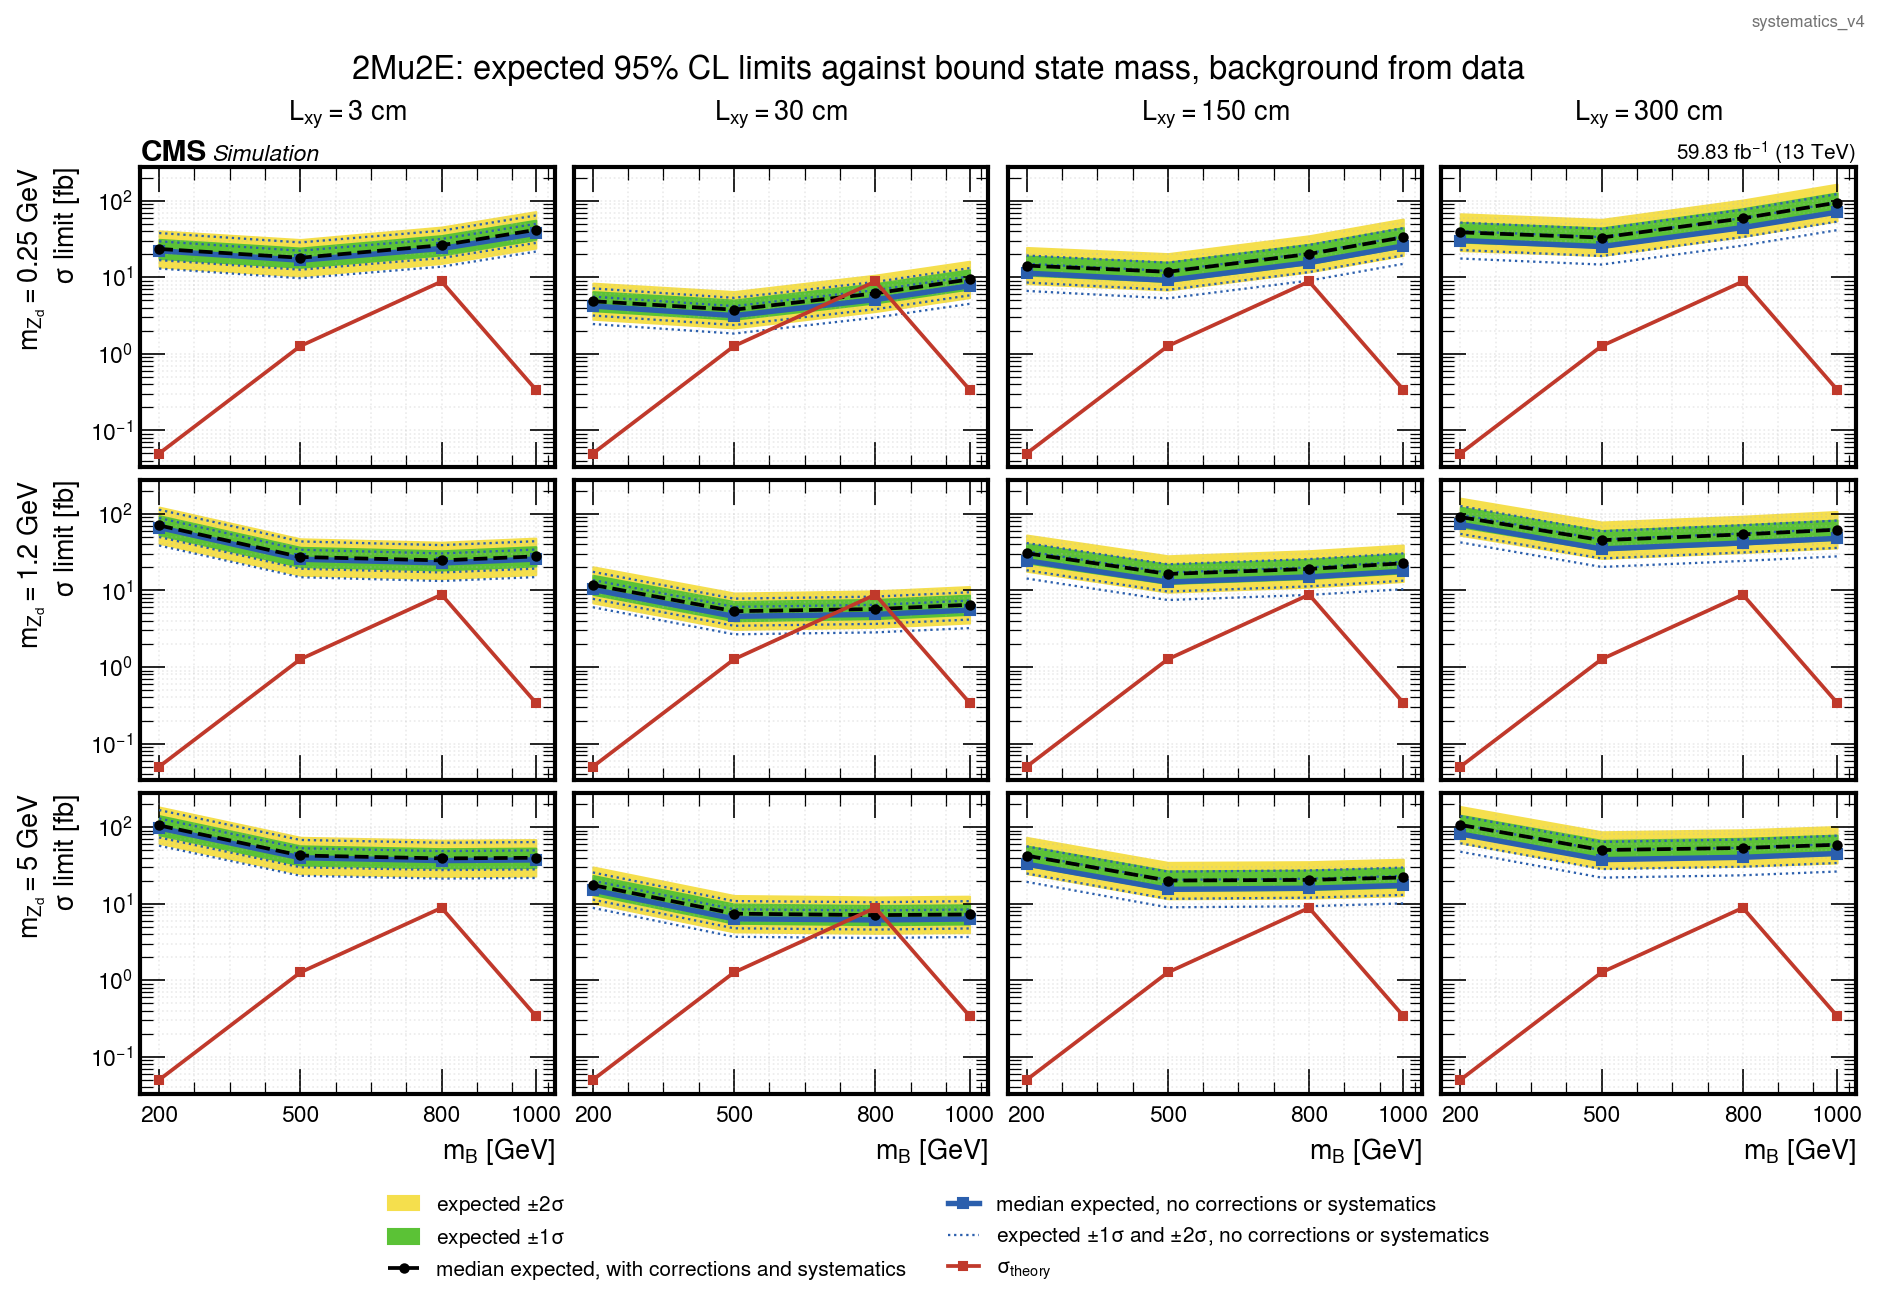

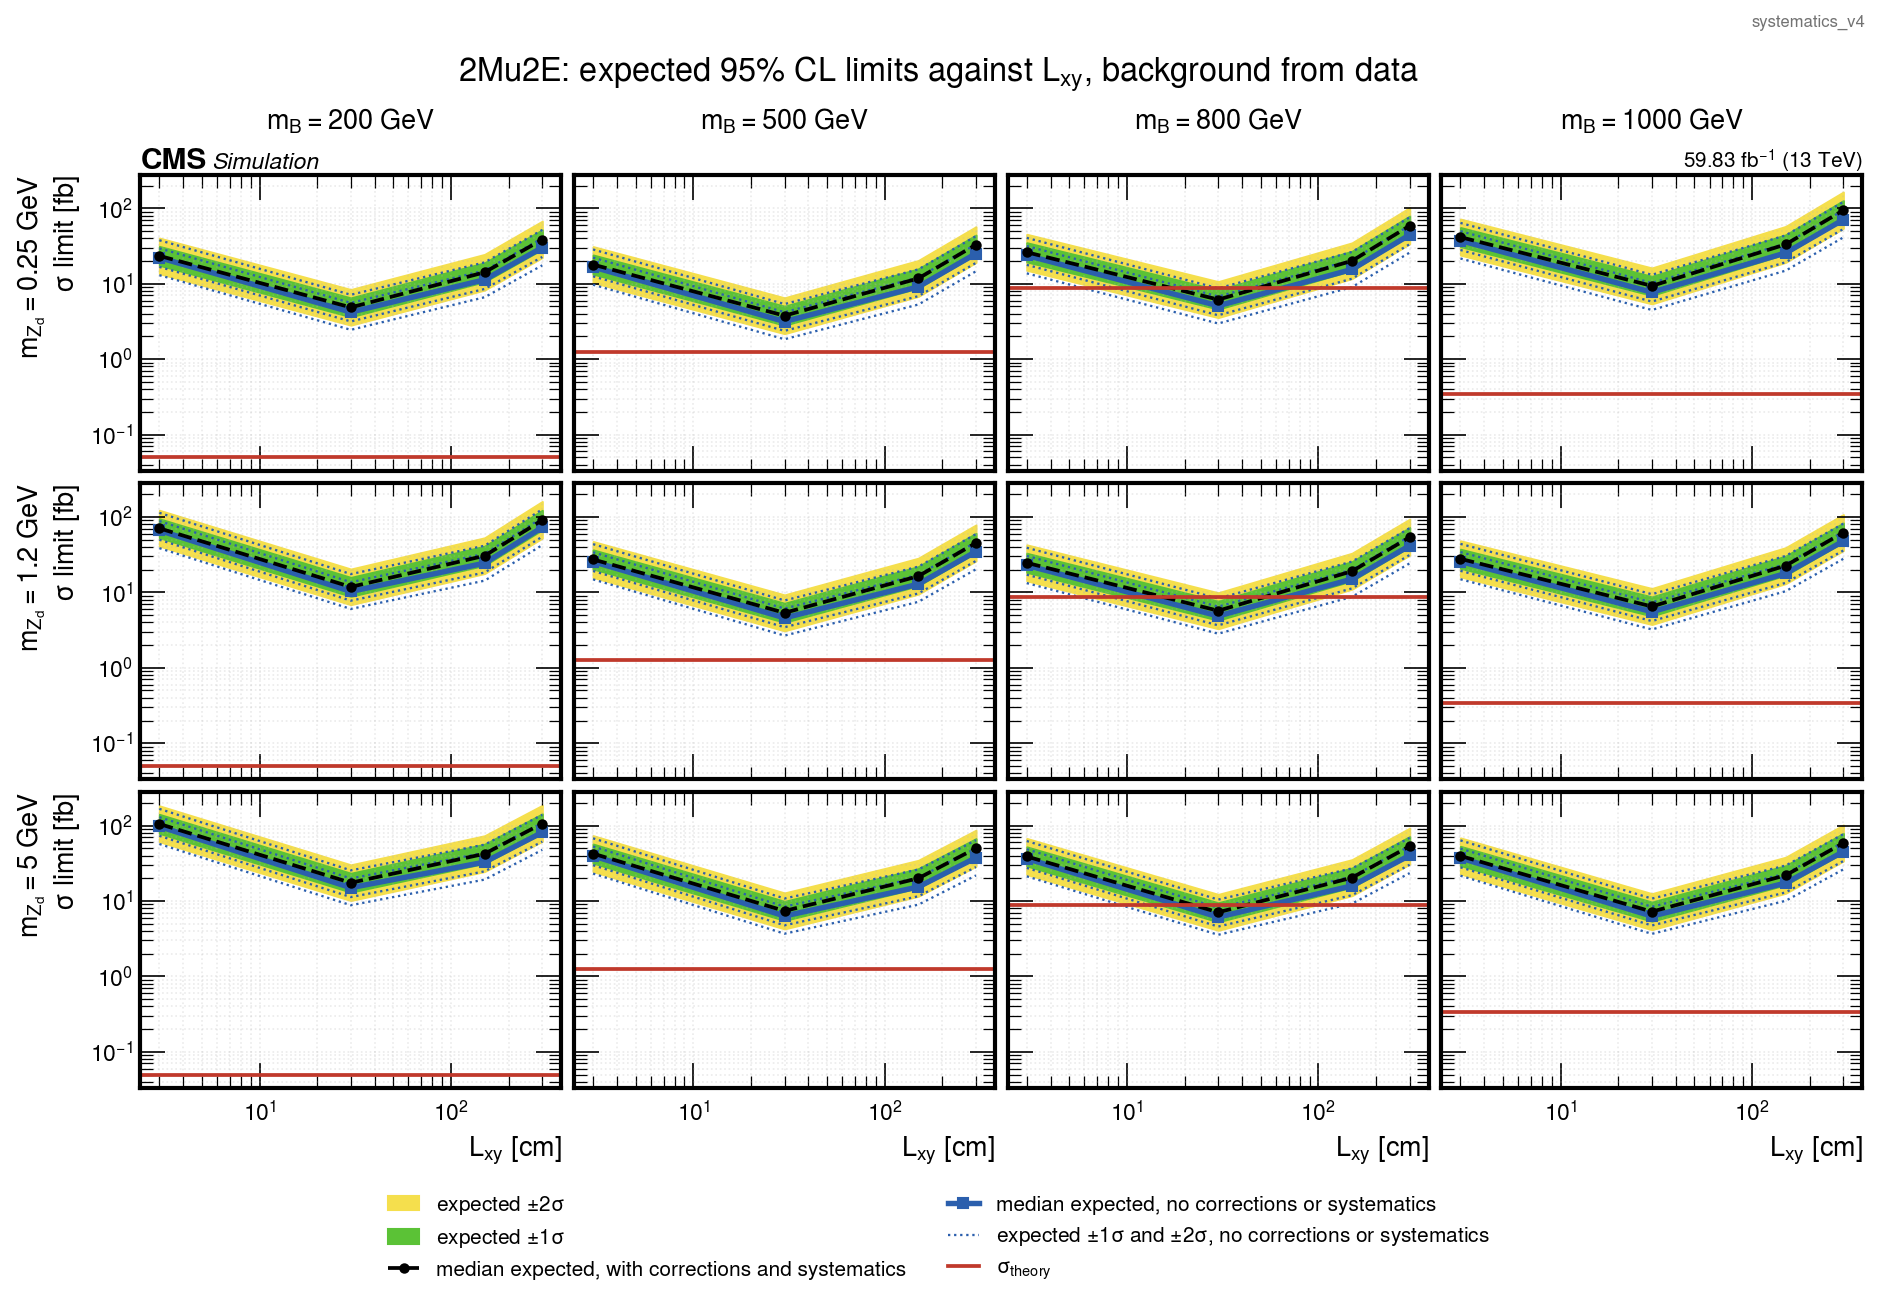

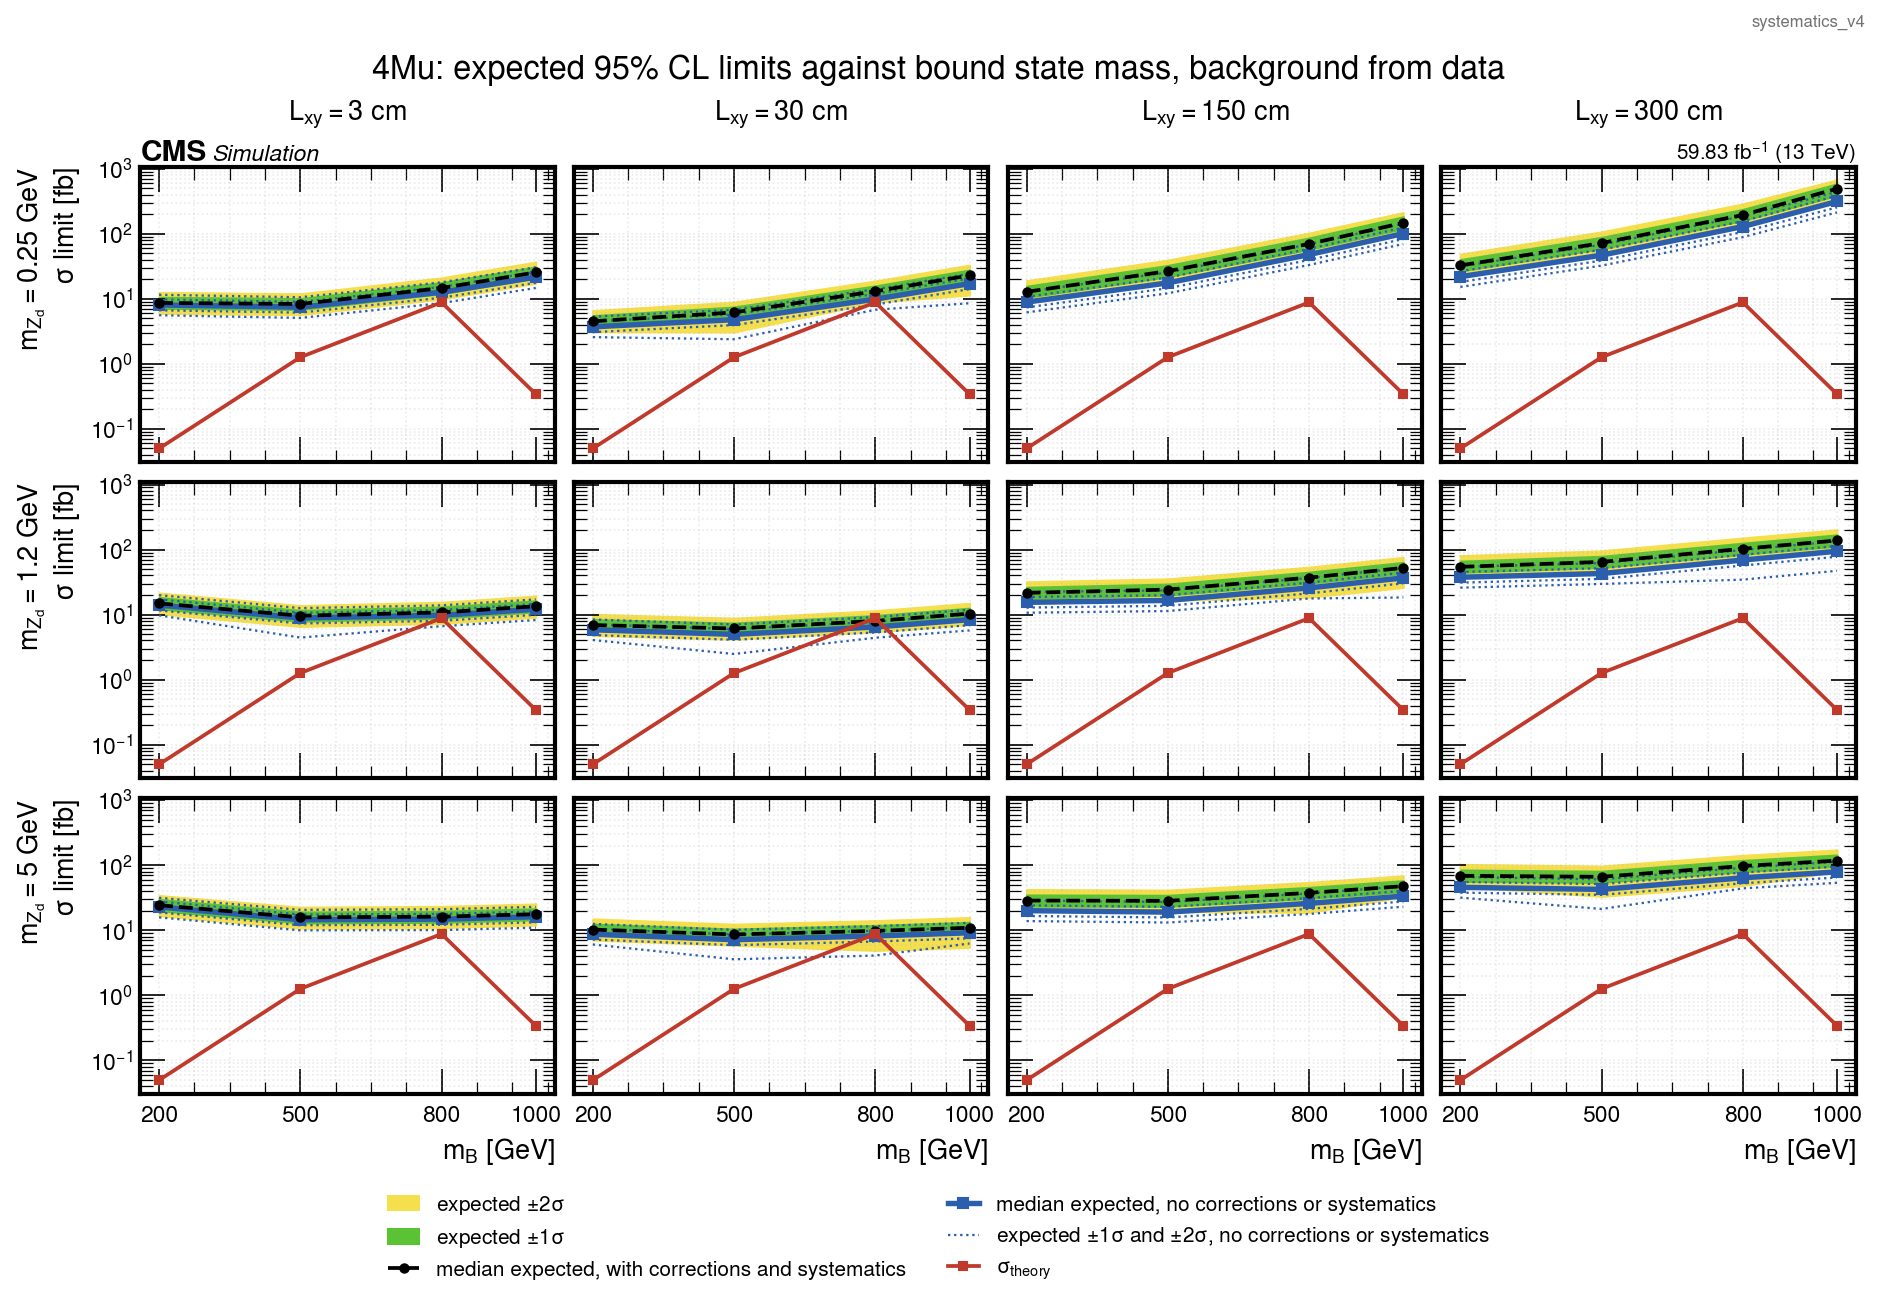

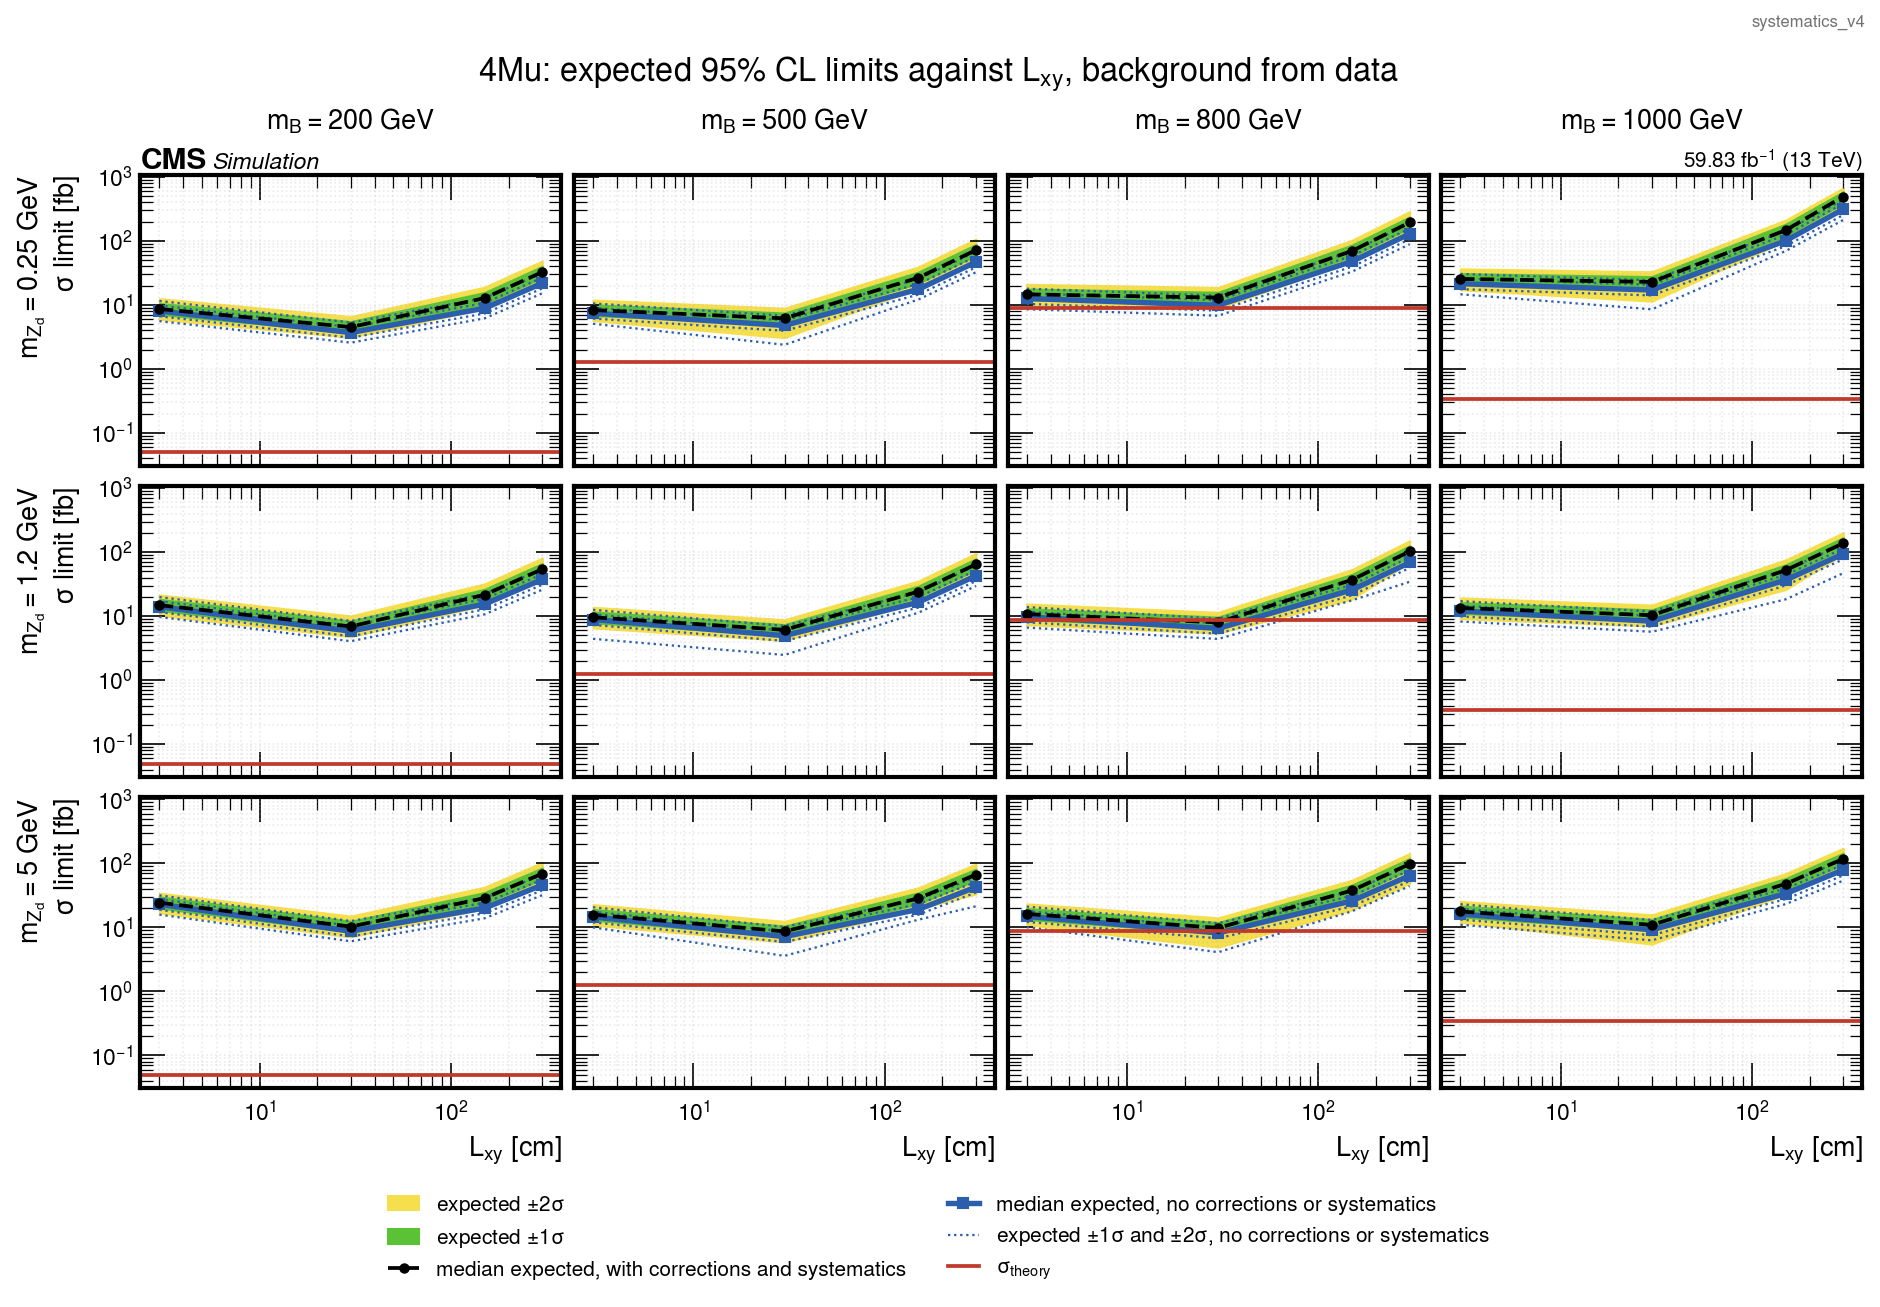

integrated 2Mu2E: expected limit with / without corrections and systematics: median 1.231, from 1.057 to 1.335 (48 points)
integrated 4Mu  : expected limit with / without corrections and systematics: median 1.368, from 1.063 to 1.575 (48 points)
binned     2Mu2E: expected limit with / without corrections and systematics: median 1.223, from 1.054 to 1.325 (48 points)
binned     4Mu  : expected limit with / without corrections and systematics: median 1.351, from 1.062 to 1.573 (48 points)
2Mu2E: binned / integrated expected limit (with): median 0.182, from 0.089 to 0.686
4Mu  : binned / integrated expected limit (with): median 0.070, from 0.026 to 0.730
with    binned     2Mu2E: excluded 14 of 48 {200: 0, 500: 2, 800: 12, 1000: 0}; best 0.654 fb (2Mu2E_1000GeV_1p2GeV_0p96mm)
with    binned     4Mu  : excluded 17 of 48 {200: 0, 500: 5, 800: 12, 1000: 0}; best 0.276 fb (4Mu_800GeV_1p2GeV_1p2mm)
with    integrated 2Mu2E: excluded 3 of 48 {200: 0, 500: 0, 800: 3, 1000: 0}; best 3.77 fb (2Mu2

In [5]:
FIGURES = WORK / "figures"
for final_state in ("2Mu2E", "4Mu"):
    for against, what in (("m_bound", "bound state mass"), ("lxy", "$L_{xy}$")):
        path = pt.brazil_grid(rows[("with", "integrated")], final_state, FIGURES, CAMPAIGN, against=against,
                              overlay=rows[("without", "integrated")], overlay_label=SETS["without"]["label"],
                              label_median=f"median expected, {SETS['with']['label']}",
                              title=f"{final_state}: expected 95% CL limits against {what}, background from data",
                              name=f"limits_vs_{against}_{final_state}")
        display(Image(filename=str(path.with_suffix(".png"))))
sysstudy.upload(FIGURES, f"{OUTPUT_DIR}/figures")

for method in METHODS:
    without = {r["signal"]: r["exp"] for r in rows[("without", method)]}
    for final_state in ("2Mu2E", "4Mu"):
        ratio = np.array([r["exp"] / without[r["signal"]] for r in rows[("with", method)]
                          if r["fs"] == final_state and r["signal"] in without])
        if len(ratio):
            print(f"{method:10s} {final_state:5s}: expected limit with / without corrections and systematics: "
                  f"median {np.median(ratio):.3f}, from {ratio.min():.3f} to {ratio.max():.3f} ({len(ratio)} points)")

integrated = {r["signal"]: r["exp"] for r in rows[("with", "integrated")]}
for final_state in ("2Mu2E", "4Mu"):
    ratio = np.array([r["exp"] / integrated[r["signal"]] for r in rows[("with", "binned")]
                      if r["fs"] == final_state and r["signal"] in integrated])
    if len(ratio):
        print(f"{final_state:5s}: binned / integrated expected limit (with): median {np.median(ratio):.3f}, "
              f"from {ratio.min():.3f} to {ratio.max():.3f}")

theory = pt.theory_xs_fb()
for (name, method), rs in sorted(rows.items()):
    for final_state in ("2Mu2E", "4Mu"):
        pts = [r for r in rs if r["fs"] == final_state and r["signal"] in theory]
        excluded = [r for r in pts if r["exp"] < theory[r["signal"]]]
        by_mass = {m: sum(1 for r in excluded if f"_{m}GeV_" in r["signal"]) for m in (200, 500, 800, 1000)}
        best = min(pts, key=lambda r: r["exp"]) if pts else None
        print(f"{name:7s} {method:10s} {final_state:5s}: excluded {len(excluded)} of {len(pts)} {by_mass}; "
              f"best {best['exp']:.3g} fb ({best['signal']})" if best else "")

**Interpretation.** With the background from data, the corrections and systematics raise the
expected limits by a median of 23% for 2Mu2E (6 to 34%) and 37% for 4Mu (6 to 58%) with the
integrated estimate, and by 22% and 35% with the binned one. This is the loss of signal from the
corrections, most of it the DSA-muon scale factor: the background comes from data and does not move
with them. The systematics alone move the limits by about half a percent (notebook 04). With them,
one 4Mu point fewer is expected to be excluded with the integrated estimate (800 GeV, 5 GeV, 30 cm),
and two fewer with the binned one (1000 GeV, 1.2 and 5 GeV, 30 cm).

The two estimates differ far more than the two sets:
* **Integrated** (the AN's likelihood): 3 of 48 points are expected to be excluded for 2Mu2E and
  1 of 48 for 4Mu, all at 800 GeV and 30 cm. The best limits are 3.8 fb (2Mu2E, 500 GeV,
  $m_{Z_d}$ = 0.25 GeV, 30 cm) and 4.5 fb (4Mu, 200 GeV, 0.25 GeV, 30 cm).
* **Binned**: the limits are a median 5.5 (2Mu2E) and 14 (4Mu) times lower, since the signal of
  the heavier points lies above 600 GeV, where B, C and D in data are nearly empty and the
  predicted background small. 14 and 17 of 48 points are expected to be excluded, every point at
  800 GeV and some at 500 GeV; the best limits are 0.65 fb (2Mu2E, 1000 GeV, 1.2 GeV, 30 cm) and
  0.28 fb (4Mu, 800 GeV, 1.2 GeV, 30 cm).

Against $L_{xy}$ the limits are best at 30 cm and weaken towards 300 cm in every panel; with the
integrated estimate those at 3 cm are a median 5.0 (2Mu2E) and 1.6 (4Mu) times those at 30 cm.
With the integrated estimate the 4Mu limits are a median 1.36 times the 2Mu2E ones (lower at 21 of
48 points), since the 4mu prediction, 70 events, is above the 2mu2e one, 45, and the DSA-muon
scale factor lowers the 4Mu signal more; with the binned estimate they are 0.61 times them (lower
at 45 of 48).

**Against `systematics_v3`** (the same selection and data, without the DSA-muon scale factor and
the lepton-jet terms), the expected limits with corrections and systematics are a median 17%
higher for 2Mu2E (4 to 26%) and 35% higher for 4Mu (4 to 56%) with the integrated estimate, and
17% and 34% with the binned one.

**For the analysis:** the corrections now cost 6 to 58% of sensitivity, most of it the
reconstruction of DSA muons, which the simulation overestimates by about 14% per DSA muon; the
systematics cost about half a percent. Which estimate the analysis uses still matters more: the
binned one is validated with the agreed 20% per-bin uncertainty in 2mu2e (AN Sec. 8, appendix),
and in 4mu its high-mass bins rest on control regions that are empty there.


## 5. Nuisance pulls

The pulls of the constrained nuisances in the fit of one point's card with the corrections and
systematics and the integrated estimate (`sidm/scripts/run_combine_pulls.py`): Combine's
`FitDiagnostics` on the expected background-only (Asimov) dataset, as a blinded analysis does,
in the background-only and the signal-plus-background fit. Each marker is the fitted value
relative to the pre-fit one, in units of the pre-fit uncertainty, with the post-fit uncertainty
as its error bar: on the Asimov dataset the pulls are zero by construction, and an error bar
shorter than one would mean the fit constrains that nuisance beyond its pre-fit uncertainty.
The free background parameters of the ABCD model are not shown, since they have no pre-fit
constraint.

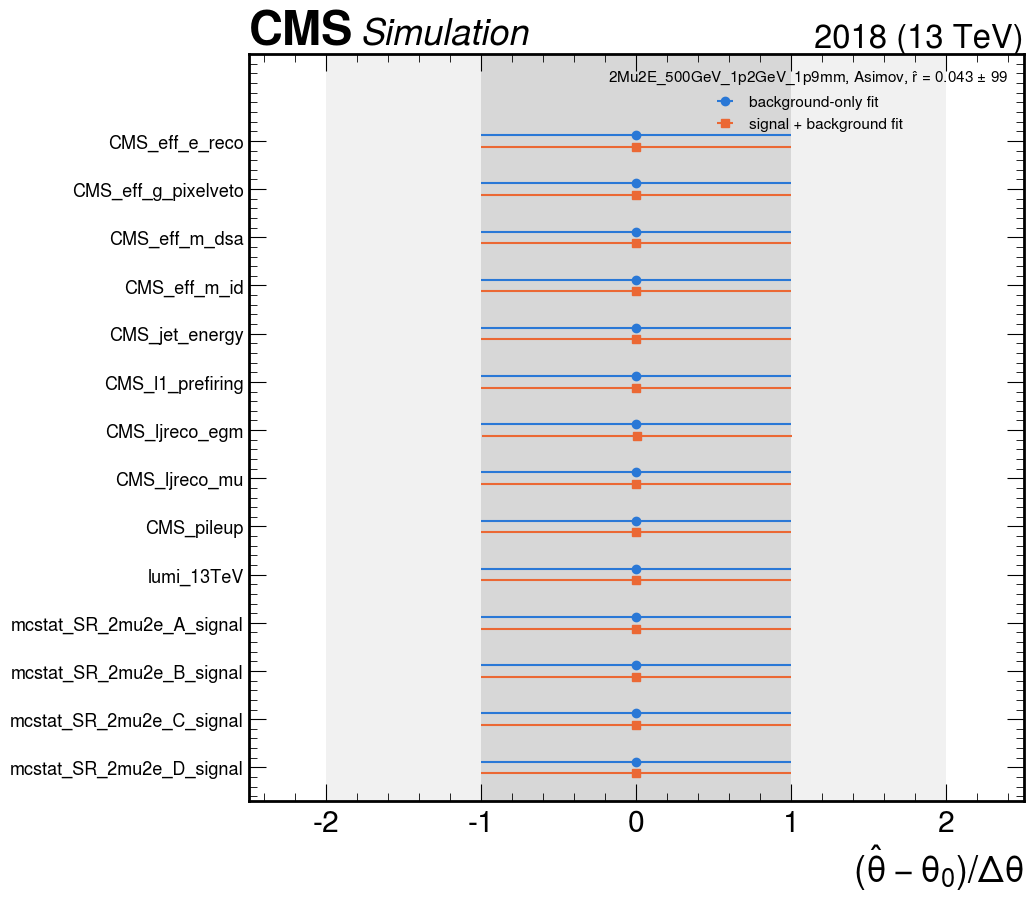

fit status (0 is success): {'fit_b': 0, 'fit_s': 0}


In [6]:
channel, point = PULLS_POINT
card = WORK / f"cards_with_{sysstudy.LIMITS_METHOD}" / f"datacard_shape_{channel}_{point}.txt"
sysstudy.run_script("run_combine_pulls.py", card, "--outdir", WORK / f"pulls_{point}",
                    combine=COMBINE, log=WORK / f"pulls_{point}.log")
sysstudy.upload(WORK, OUTPUT_DIR)
with fsspec.open(f"{OUTPUT_DIR}/pulls_{point}/pulls.json") as f:
    pulls = json.load(f)
names = sorted(pulls["nuisances"], key=lambda n: (n.startswith("mcstat"), n))

fig, ax = plt.subplots(figsize=(10, 2 + 0.55 * len(names)))
y = np.arange(len(names))[::-1]
for band, alpha in ((2, 0.12), (1, 0.25)):
    ax.axvspan(-band, band, color=GRAY, alpha=alpha, lw=0)
for fit, offset, color, marker, label in (("fit_b", 0.12, BLUE, "o", "background-only fit"),
                                          ("fit_s", -0.12, ORANGE, "s", "signal + background fit")):
    pull = [(pulls["nuisances"][n][fit][0] - pulls["nuisances"][n]["prefit"][0]) / pulls["nuisances"][n]["prefit"][1]
            for n in names]
    error = [pulls["nuisances"][n][fit][1] / pulls["nuisances"][n]["prefit"][1] for n in names]
    ax.errorbar(pull, y + offset, xerr=error, fmt=marker, color=color, ms=6, label=label)
ax.set_yticks(y)
ax.set_yticklabels(names, fontsize=13)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-0.7, len(names) + 0.8)    # room for the legend above the first row
ax.set_xlabel(r"$(\hat\theta - \theta_0)/\Delta\theta$")
r_fit = pulls["r"].get("fit_s", [float("nan")] * 2)
ax.legend(title=f"{point}, Asimov, $\\hat r$ = {r_fit[0]:.2g} $\\pm$ {r_fit[1]:.2g}", fontsize=11,
          title_fontsize=11, loc="upper right")
study.cms_label(ax)
plt.show()
print("fit status (0 is success):", pulls["status"])

**Interpretation.** Every nuisance sits at zero with its full pre-fit uncertainty in both fits,
which both converge. That is expected and is not a problem: the constrained nuisances of these
cards all act on the signal alone, so a fit without signal carries no information on them, and
with the signal floating they cannot be told apart from $r$. The ±106 on $\hat r$ is not an
uncertainty: $r$ is kept at or above 0, the fit to a background-only dataset lands on that
boundary, and there the fitter's parabolic error means nothing.

**For the analysis:** this plot shows nothing new until nuisances on the background enter, for
example the agreed 20% per-bin uncertainty of the region-A prediction. What each systematic does
to $r$ is in the impacts of notebook 04.

Everything is on EOS now, so the local working directory goes.

In [7]:
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v4_limits_data


## Adding a systematic

1. Add an entry to `systematics.yaml`: `flat` for a fixed value, `syst` for a correction
   whose up and down weight categories the campaign stored, `variant` for a histogram
   filled with a varied input (as `abcd6d_*_iso_up` is for the jet energy), or `per_lj` for a
   value per lepton jet of one type (as the lepton-jet reconstruction terms are).
2. If it needs new histograms or weight variations, add them to `hists.py` or
   `corrections.yaml` and rerun the campaign.
3. Rerun this notebook, and describe the new source in `README.md`.